In [1]:
import numpy as np

# 1. Corpus definition
# corpus = [
#     "I do not like computer science",
#     "ok I will like computer science",
#     "may be in a year I will like computer science",
#     "I was lying I will not like computer science"
# ]
corpus = [
    # Gender / Royalty pairs
    "king is male and rules the kingdom",
    "queen is female and rules the kingdom",
    "man is a male person",
    "woman is a female person",
    "boy is a young male",
    "girl is a young female",
    "prince is a young king and male",
    "princess is a young queen and female",
    # Computer / Science / Tech context
    "i do not like computer science",
    "ok i will like computer science",
    "may be in a year i will like computer science",
    "i was lying i will not like computer science",
    "computer science is a great field",
    "technology and science are useful",
]

# Hyperparameters
c = 2      # Window size
d = 50      # Embedding dimension
eta = 0.01 # Learning rate
T = 100    # Epochs

# --- 1. Build Vocabulary V ---
words = [word.lower() for doc in corpus for word in doc.split()]
vocab = list(set(words))
vocab_size = len(vocab)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for i, w in enumerate(vocab)}

# --- 2 & 3. Initialize Embeddings E and Weights W ---
np.random.seed(42)
E = np.random.randn(vocab_size, d) * 0.01
W = np.random.randn(d, vocab_size) * 0.01

def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum(axis=0)

# --- 5. Training Loop ---
for epoch in range(T):
    # --- 4. Generate Training Pairs ---
    pairs = []
    for sentence in corpus:
        tokens = sentence.lower().split()
        for i, word in enumerate(tokens):
            center_idx = word2idx[word]
            for j in range(max(0, i - c), min(len(tokens), i + c + 1)):
                if i != j:
                    context_idx = word2idx[tokens[j]]
                    pairs.append((center_idx, context_idx))

    # Shuffle training pairs
    np.random.shuffle(pairs)

    for center, context in pairs:
        # Forward pass
        h = E[center]                  # Vector shape (d,)
        scores = np.dot(h, W)          # Vector shape (vocab_size,)
        probabilities = softmax(scores)

        # Loss computation
        loss = -np.log(probabilities[context] + 1e-9)

        # Backpropagation
        error = probabilities.copy()
        error[context] -= 1.0

        gradient_W = np.outer(h, error)
        gradient_h = np.dot(W, error)

        # Update parameters
        W -= eta * gradient_W
        E[center] -= eta * gradient_h

print("Learned Word Embeddings (E):")
for word in vocab:
    print(f"{word:15s}: {E[word2idx[word]]}")

Learned Word Embeddings (E):
computer       : [-0.20885847  0.09581392  0.19644882  0.88651572  0.77860328 -0.32194092
  0.52734539  0.96117771 -0.31011953  0.35908599 -0.34650331 -0.1833703
 -0.29453099  0.03053464 -0.60363312 -0.26292267 -0.06506903  0.54369222
  0.0264517  -0.19074799  0.75739188 -0.20520657  0.18883066 -0.75673303
 -0.71000727 -0.08586574 -0.46917115  0.06993981 -0.19140542 -0.0643711
 -0.25841098  0.56518379  0.44475431 -0.06764647  0.3883984  -0.30136107
 -0.01585788 -0.39537617 -0.37281899 -0.21676628 -0.11268207  0.02739257
 -0.26172963  0.02143687 -0.04249827 -0.52110636  0.03867491  0.17387247
 -0.00625429 -0.03028308]
i              : [ 0.42420971  0.41221301 -0.15388724  0.19507557  0.17173783 -0.11332148
  0.19276263  0.04846959  0.60633692  0.50056095 -0.32109782  0.04117129
 -0.32012958 -0.66589354 -0.19441835  0.02738805 -0.23658051 -0.0299997
 -0.41757948 -0.17547862 -0.05406321  0.39891939  0.32147971  0.07851312
 -0.51853016 -0.11513008 -0.46270064 -

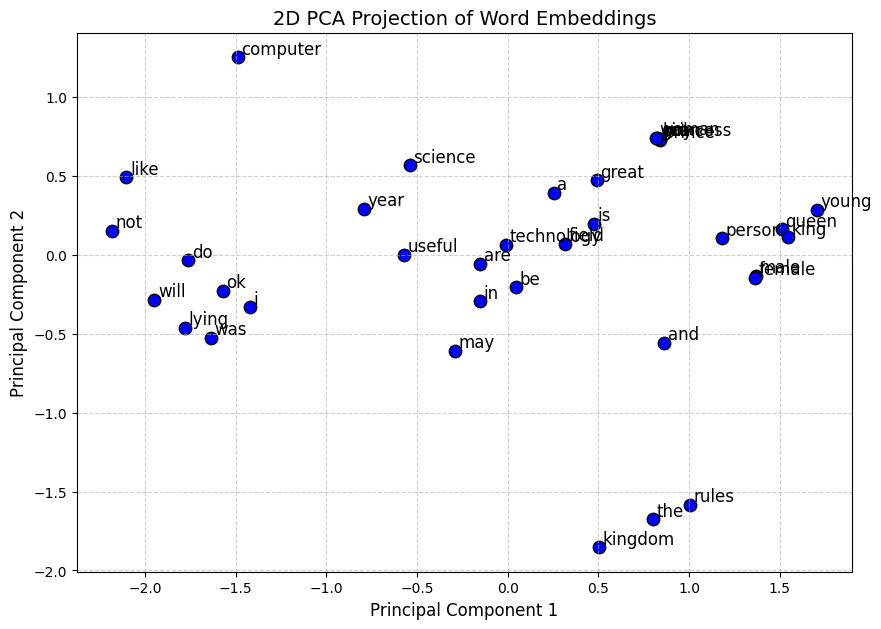

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# 1. Extract vocabulary words and their corresponding 5D vectors
words = list(vocab)
matrix_E = np.array([E[word2idx[w]] for w in words])

# 2. Reduce 5D -> 2D using PCA
pca = PCA(n_components=2)
coords_2d = pca.fit_transform(matrix_E)

# 3. Create the scatter plot
plt.figure(figsize=(10, 7))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color="blue", edgecolors="k", s=80)

# 4. Annotate each point with its word label
for i, word in enumerate(words):
    plt.annotate(
        word, (coords_2d[i, 0] + 0.02, coords_2d[i, 1] + 0.02), fontsize=12
    )

plt.title("2D PCA Projection of Word Embeddings", fontsize=14)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()